# 01 · Corpus exploration and selection (Phase 1)

**Goal:** understand the raw business-aid data, justify every cleaning and selection decision, and end with the
final corpus used by the assistant: **504 aids** on green transition and innovation (`data/processed/aids.jsonl`).

The notebook **does not write any file**. It reuses the project's own pipeline (`src/aides_rag/ingest/select_subset.py`),
so every number here is the number the system actually uses.

| # | Section | Question it answers |
|---|---|---|
| 1 | Source and snapshot | Where does the data come from, and is it the frozen snapshot? |
| 2 | Loading | How do we read these files correctly? |
| 3 | The 9 files | How do the files relate to each other? |
| 4 | Missing values | Which columns do we keep? |
| 5 | Text quality | How much cleaning is needed? |
| 6 | Document length | Which aids are too thin, and how should we chunk? |
| 7 | Near-duplicates | Which documents would pollute retrieval? |
| 8 | Metadata | Which filters can the assistant offer? |
| 9 | Theme choice | Why green transition + innovation? |
| 10 | Selection pipeline | How do we get from 2,442 to 504 aids? |
| 11 | Region resolution | Where is each aid available, and what was wrong in the source? |
| 12 | Joins | How do IDs become readable labels? |
| 13 | Reproducibility | Does a rebuild give exactly the committed file? |
| 14 | Final corpus profile | What does the corpus look like? |
| 15 | Golden set | What will we evaluate on? |
| 16 | Known limitations | What should the jury know? |
| 17 | **Final dataset** | `df.head()` of the corpus |

**Requirement:** the raw CSV snapshot in `data/raw/` (git-ignored; see `data/raw/README.md`).
Run with `uv sync --group notebooks`, then open this notebook with the project's `.venv` kernel.

In [13]:
import hashlib
import json
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
# Make src/ importable even when the kernel is not the project's .venv
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aides_rag.ingest import select_subset as sel

RAW, PROCESSED = ROOT / "data" / "raw", ROOT / "data" / "processed"
assert (RAW / "aides.csv").exists(), "Put the raw CSV snapshot in data/raw/ (see data/raw/README.md)"

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

# One palette for every chart: blue = main data, orange = highlight, grey = discarded / other
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "x", "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
})

def label_hbars(ax, fmt="{:,.0f}", pad=0.01):
    """Write each horizontal bar's value at its end."""
    xmax = ax.get_xlim()[1]
    for p in ax.patches:
        w = p.get_width()
        ax.text(w + xmax * pad, p.get_y() + p.get_height() / 2, fmt.format(w), va="center", fontsize=9, color=INK)

## 1. Source and snapshot

| | |
|---|---|
| Dataset | **"Aides entreprises"**: https://www.data.gouv.fr/datasets/aides-entreprises |
| Publisher | Institut Supérieur des Métiers. The aides-entreprises.fr database was set up by the French government |
| Licence | **Licence Ouverte / Open Licence** (`fr-lo`, v1.0), as declared on the dataset page. Attribution required |
| Snapshot | Files received 2026-10-13. The official files update weekly, so the project keeps this snapshot **frozen** |

First check: are the files in `data/raw/` the exact snapshot the corpus was built from? Their SHA-256 must match `selection_report.json`.

In [14]:
report = json.loads((PROCESSED / "selection_report.json").read_text(encoding="utf-8"))
pd.DataFrame([
    {"file": f.name, "size (KB)": round(f.stat().st_size / 1024),
     "matches frozen snapshot": hashlib.sha256(f.read_bytes()).hexdigest() == report["raw_sha256"].get(f.name)}
    for f in sorted(RAW.glob("*.csv"))
])

,file,size (KB),matches frozen snapshot
0,aides.csv,5867,True
1,contacts.csv,2128,True
2,domaines.csv,0,True
3,financeurs.csv,190,True
4,natures.csv,0,True
5,niveaux.csv,0,True
6,profils.csv,2,True
7,projets.csv,6,True
8,territoires.csv,7435,True


## 2. Loading

The files are **not standard CSVs**:
- they are encoded in **Windows-1252 (cp1252)**, not UTF-8, so a default `pd.read_csv` fails or mangles accents;
- the separator is `;`;
- every line ends with `;`, which creates an empty extra column;
- text fields contain line breaks inside quotes.

`sel.read_raw` handles all four. It keeps empty fields as `""` rather than `NaN`, so text can be concatenated safely.

In [15]:
raw = sel.read_raw(RAW, "aides.csv")
print(f"{raw.shape[0]:,} aids × {raw.shape[1]} columns")
raw.head(3)

2,442 aids × 28 columns


,id_aid,aid_nom,aid_objet,aid_operations_el,aid_conditions,aid_montant,aid_benef,aid_validation,couverture_geo,id_domaine,...,age_entreprise,complements_sources,complements_formulaires,complements_reglements,projets,profils,natures,territoires,contacts,financeurs
0,9829,Activité Partielle de Longue Durée (APLD),Offrir la possibilité à une entreprise - confrontée à une réduction durable ...,Diminution de l’horaire de travail en contrepartie d’engagements notamment e...,La réduction de l’horaire de travail d’un salarié ne peut dépasser 40 % de l...,L’employeur reçoit une allocation équivalent à une part de la rémunération h...,Toutes les entreprises - confrontées à une réduction d’activité durable - im...,2026-02-04,aide nationale,Economie,...,"- de 3 ans, + de 3 ans",Consulter la page 'L'activité partielle de longue durée rebond (APLD-R) : qu...,Déposer une demande sur le site dédié. https://activitepartielle.emploi.gouv...,,"39, 92, 134, 137","4, 5, 6, 7, 8, 9, 10, 11, 14, 15, 16, 17, 18, 19, 20",3,1,"12978, 13034, 13035, 13036, 13037, 13038, 13039, 13040, 13041, 13042, 13043,...",1287
1,12156,Activité partielle de longue durée 'Rebond',Répondre à la dégradation de la conjoncture économique et à l'augmentation d...,Soutien à la baisse d'activité due à la conjoncture économique.\nLa réductio...,La mise en place du dispositif dépend de l'accord de branche étendu ainsi qu...,"Le taux horaire de l'allocation versée à l'employeur est égal, pour chaque s...",Entreprises de toutes tailles et de tous secteurs d'activité.,2026-03-06,aide nationale,Economie,...,"- de 3 ans, + de 3 ans",Consulter la présentation de l'activité partielle de longue durée rebond (AP...,,,"40, 92, 134, 137","4, 5, 6, 7, 8, 9, 10, 11, 14, 15, 16, 17, 18, 19, 20",3,1,"11360, 11361, 11364, 11365, 11366, 11367, 11368, 11369, 11370, 11371, 11372,...",1287
2,8649,Aide Régionale au Démarrage et au Développement d'Activités (ARDDA),Soutenir les projets de création et de développement de très petites entrepr...,"Acquisition de matériel d’équipement, matériel de production ;\nTravaux d'am...",Le bénéficiaire devra :\n- maintenir son activité pendant au moins trois ans...,"Subvention plafonnée à 10 000 €, calculée en fonction du montant total des i...",Entreprises en création et en développement de moins de 5 salariés.\nActivit...,2026-06-26,aide territoriale,Economie,...,"- de 3 ans, + de 3 ans",Consulter la fiche du dispositif AIDE REGIONALE AU DEMARRAGE ET AU DEVELOPPE...,Faire une demande en ligne sur le Portail des aides régionales de la Guadelo...,,"6, 76, 134, 135","4, 5, 6, 8, 15, 16, 17, 18, 19",3,121,"6590, 12978",573


## 3. The 9 files and how they relate

`aides.csv` is the main table: one row per aid. Several of its columns hold **lists of IDs** (e.g. `natures = "3, 14"`)
that point to small lookup tables. Without those tables the IDs mean nothing to a user, so the pipeline joins them
(section 12).

In [16]:
proj_label, proj_parent = sel.load_projets(RAW)
files = [
    ("aides.csv", len(raw), "main table: one row per aid", "—", "kept"),
    ("natures.csv", len(sel.read_raw(RAW, "natures.csv")), "aid type (grant, loan…)", "aides.natures → id_typ", "joined"),
    ("projets.csv", len(proj_label), "91 project themes under 10 parent categories", "aides.projets → id", "joined"),
    ("profils.csv", len(sel.read_raw(RAW, "profils.csv")), "eligible business profiles", "aides.profils → id_tut", "joined"),
    ("financeurs.csv", len(sel.read_raw(RAW, "financeurs.csv")), "funders (name, postcode, level)", "aides.financeurs → id_org", "joined"),
    ("territoires.csv", len(sel.read_raw(RAW, "territoires.csv")), "areas: regions, departments, communes", "aides.territoires → id_ter", "joined (with fixes)"),
    ("contacts.csv", len(sel.read_raw(RAW, "contacts.csv")), "contact offices", "aides.contacts → id_cnt", "IDs kept only"),
    ("domaines.csv", len(sel.read_raw(RAW, "domaines.csv")), "domain names", "already written in aides.id_domaine", "not used"),
    ("niveaux.csv", len(sel.read_raw(RAW, "niveaux.csv")), "national / regional / EU", "already written in aides.couverture_geo", "not used"),
]
pd.DataFrame(files, columns=["file", "rows", "content", "join key", "use"])

,file,rows,content,join key,use
0,aides.csv,2442,main table: one row per aid,—,kept
1,natures.csv,12,"aid type (grant, loan…)",aides.natures → id_typ,joined
2,projets.csv,91,91 project themes under 10 parent categories,aides.projets → id,joined
3,profils.csv,17,eligible business profiles,aides.profils → id_tut,joined
4,financeurs.csv,1427,"funders (name, postcode, level)",aides.financeurs → id_org,joined
5,territoires.csv,39348,"areas: regions, departments, communes",aides.territoires → id_ter,joined (with fixes)
6,contacts.csv,7925,contact offices,aides.contacts → id_cnt,IDs kept only
7,domaines.csv,8,domain names,already written in aides.id_domaine,not used
8,niveaux.csv,3,national / regional / EU,already written in aides.couverture_geo,not used


## 4. Missing values: which columns do we keep?

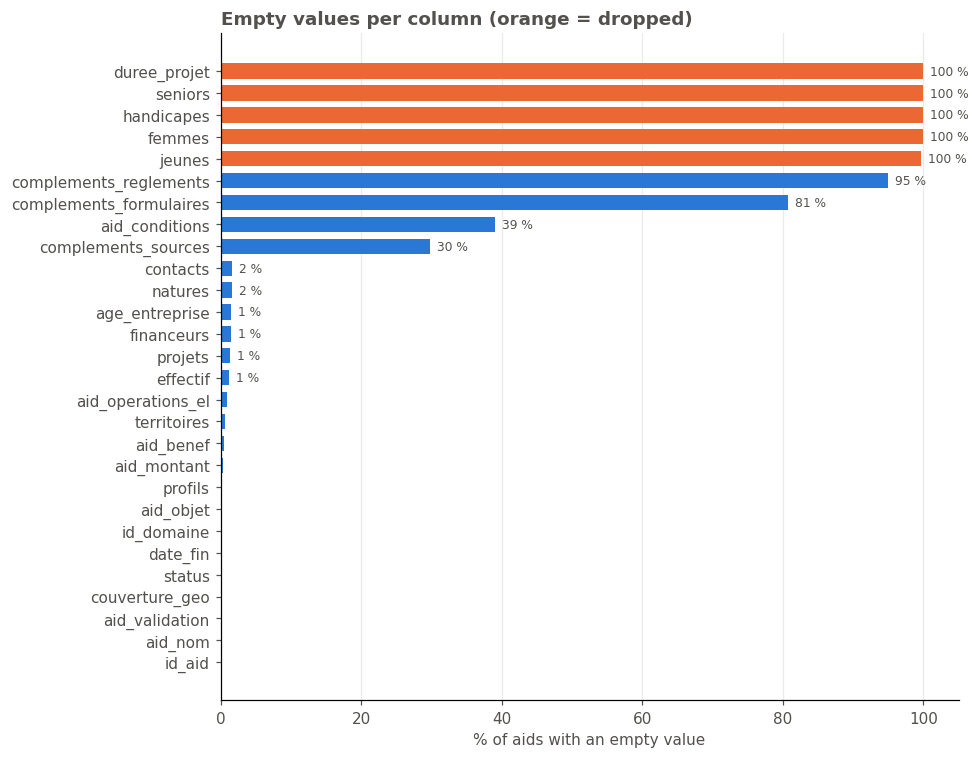

Constant columns: ['seniors', 'status', 'duree_projet']


In [17]:
empty = (raw.apply(lambda c: c.str.strip() == "").mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
DROPPED = ["handicapes", "femmes", "seniors", "jeunes", "duree_projet", "status"]
ax.barh(empty.index, empty.values, color=[ORANGE if c in DROPPED else BLUE for c in empty.index], height=0.7)
ax.set_xlim(0, 105)
ax.set_xlabel("% of aids with an empty value")
ax.set_title("Empty values per column (orange = dropped)")
for y, v in enumerate(empty.values):
    if v >= 1:
        ax.text(v + 1, y, f"{v:.0f} %", va="center", fontsize=8)
plt.tight_layout(); plt.show()

print("Constant columns:", [c for c in raw.columns if raw[c].nunique() == 1])

**Decision.**
- The core text fields (`aid_nom`, `aid_objet`, `aid_montant`, `aid_benef`) are almost always filled: they are what the assistant reads.
- `aid_conditions` is empty for about 4 aids in 10. Eligibility rules then often sit in `aid_benef` or `aid_montant`, so all text fields are kept together.
- `handicapes`, `femmes`, `seniors`, `jeunes`, `duree_projet` are more than 99 % empty, and `status` is constant: **dropped**.

## 5. Text quality

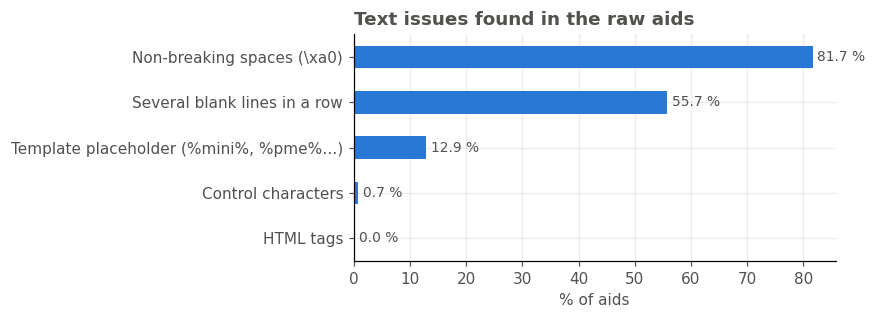

Field 'aid_objet', around the first non-breaking space:
BEFORE: ' nature à compromettre leur pérennité.\n\n\xa0\nLes accords collectifs et les documents unilatér'
AFTER:  'nature à compromettre leur pérennité.\n\nLes accords collectifs et les documents unilatér'


In [18]:
text = raw[sel.LENGTH_FIELDS].agg(" ".join, axis=1)
checks = pd.Series({
    "Non-breaking spaces (\\xa0)": text.str.contains("\xa0"),
    "Several blank lines in a row": text.str.contains(r"\n\s*\n\s*\n"),
    "Control characters": text.str.contains(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]"),
    "HTML tags": text.str.contains(r"<[a-zA-Z/][^>]*>"),
    "Template placeholder (%mini%, %pme%…)": text.str.contains(r"%\w+%"),
}).map(lambda s: s.mean() * 100).sort_values()

ax = checks.plot.barh(color=BLUE, figsize=(8, 3))
ax.set_xlabel("% of aids"); ax.set_title("Text issues found in the raw aids")
label_hbars(ax, "{:.1f} %"); plt.tight_layout(); plt.show()

col = next(c for c in sel.LENGTH_FIELDS if raw[c].str.contains("\xa0").any())
example = raw.loc[raw[col].str.contains("\xa0").idxmax(), col]
start = max(example.index("\xa0") - 40, 0)
print(f"Field {col!r}, around the first non-breaking space:")
print("BEFORE:", repr(example[start:start + 90]))
print("AFTER: ", repr(sel.clean_text(example[start:start + 90])))

**Decision.** The text is already clean: no HTML, almost no control characters. A **light** cleaning is enough:
- normalise spaces;
- remove control characters;
- collapse blank lines.

Line breaks are kept, because they separate lists and paragraphs, which helps chunking.
`%mini%` (*de minimis* rule) and `%pme%` (SME definition) are template tokens of the source website. They will be expanded at chunking time (Phase 2).

## 6. Document length

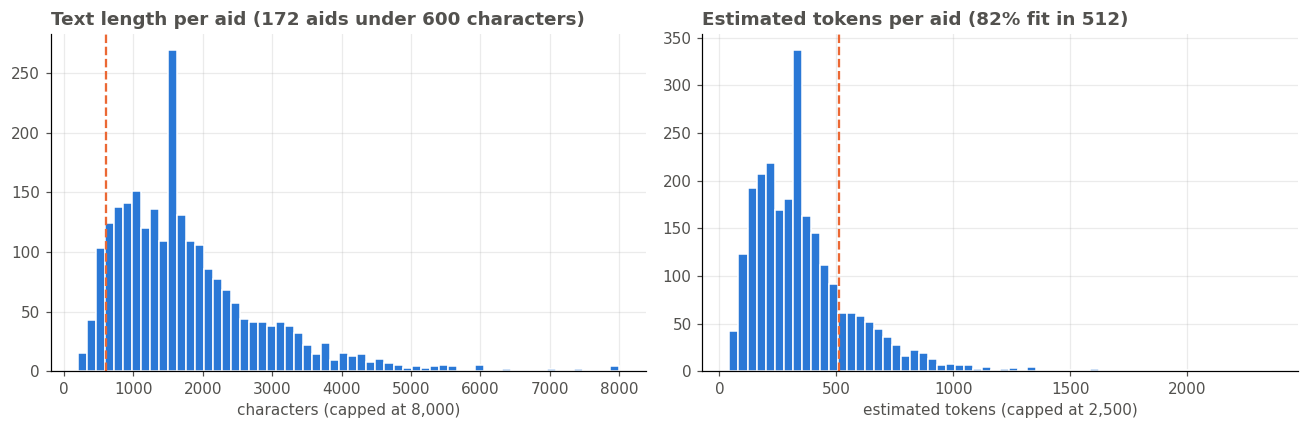

Shortest aid kept vs. a dropped one:
  [8668] 600 chars | Aide régionale au développement des installations solaires thermiques
  [11032] 196 chars | Pacte création - Prime pour les moins de 30 ans


In [19]:
n_chars = text.str.len()
n_tokens = (text.str.split().str.len() / 0.75).round()  # rough rule for French: 1 token ≈ 0.75 word

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(n_chars.clip(upper=8000), bins=60, color=BLUE, edgecolor="white")
axes[0].axvline(sel.MIN_CHARS, color=ORANGE, ls="--", lw=1.5)
axes[0].set_title(f"Text length per aid ({(n_chars < sel.MIN_CHARS).sum()} aids under {sel.MIN_CHARS} characters)")
axes[0].set_xlabel("characters (capped at 8,000)"); axes[0].grid(axis="y", alpha=0.25)

axes[1].hist(n_tokens.clip(upper=2500), bins=60, color=BLUE, edgecolor="white")
axes[1].axvline(512, color=ORANGE, ls="--", lw=1.5)
axes[1].set_title(f"Estimated tokens per aid ({(n_tokens <= 512).mean():.0%} fit in 512)")
axes[1].set_xlabel("estimated tokens (capped at 2,500)"); axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

print("Shortest aid kept vs. a dropped one:")
for i in [n_chars[n_chars >= sel.MIN_CHARS].idxmin(), n_chars.idxmin()]:
    print(f"  [{raw.at[i, 'id_aid']}] {n_chars[i]} chars | {raw.at[i, 'aid_nom'][:70]}")

**Decision.** Aids under **600 characters** are dropped. They rarely state an amount or an eligibility condition, so
they cannot answer questions. Most aids fit in one 512-token chunk; chunking options (one chunk per aid vs. one per
section) will be compared on the golden set in Phase 2.

## 7. Near-duplicates

Many aids are **the same scheme copied for different territories**. Example: the "Prêt d'honneur Initiative [territory]"
cards. If we keep all the copies, search fills its top results with clones, and retrieval scores become ambiguous: which copy is the "right" one?

Method:
1. Compute TF-IDF vectors on `objet + operations + montant`.
2. Two aids with cosine similarity **> 0.9** are near-duplicates; linked aids form a cluster.

2,189 clusters for 2,442 aids | 49 clusters with copies | 302 aids have at least one near-copy


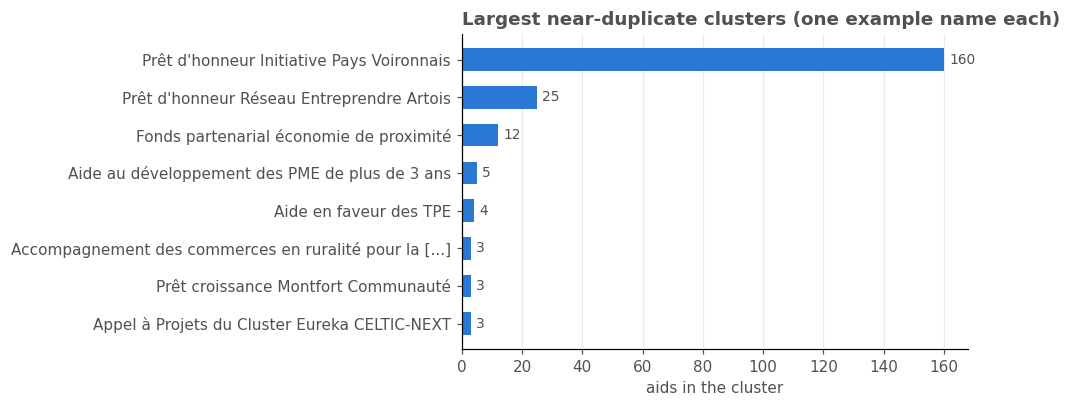

,id_aid,aid_nom,aid_validation
79,2234,Prêt d'honneur Initiative Pays Voironnais,2026-04-20
1995,2711,Prêt d'honneur Bruche Mossig Piemont Initiative,2026-04-20
2009,2152,Prêt d'honneur Indre Initiative,2026-04-20
2013,5399,Prêt d'honneur Initiative Agglomération Sophia Antipolis (IASA),2026-03-30
2014,2202,Prêt d'honneur Initiative Aisne,2026-03-30


In [20]:
clusters = pd.Series(sel.near_duplicate_clusters(raw), index=raw.index)
sizes = clusters.value_counts()
print(f"{len(sizes):,} clusters for {len(raw):,} aids | {(sizes > 1).sum()} clusters with copies | "
      f"{(clusters.map(sizes) > 1).sum()} aids have at least one near-copy")

top = sizes.head(8)
names = [textwrap.shorten(raw.loc[clusters == c, "aid_nom"].iloc[0], 55) for c in top.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(names[::-1], top.values[::-1], color=BLUE, height=0.6)
ax.set_xlabel("aids in the cluster"); ax.set_title("Largest near-duplicate clusters (one example name each)")
label_hbars(ax); plt.tight_layout(); plt.show()

raw.loc[clusters == top.index[0], ["id_aid", "aid_nom", "aid_validation"]].head(5)

**Decision.** Keep **one aid per cluster**: the most recently validated one (`aid_validation`), and on a tie, the
smallest `id_aid`. The tie-break rule was approved by the project lead on 2026-10-14 (see section 10).

## 8. Metadata available for filters

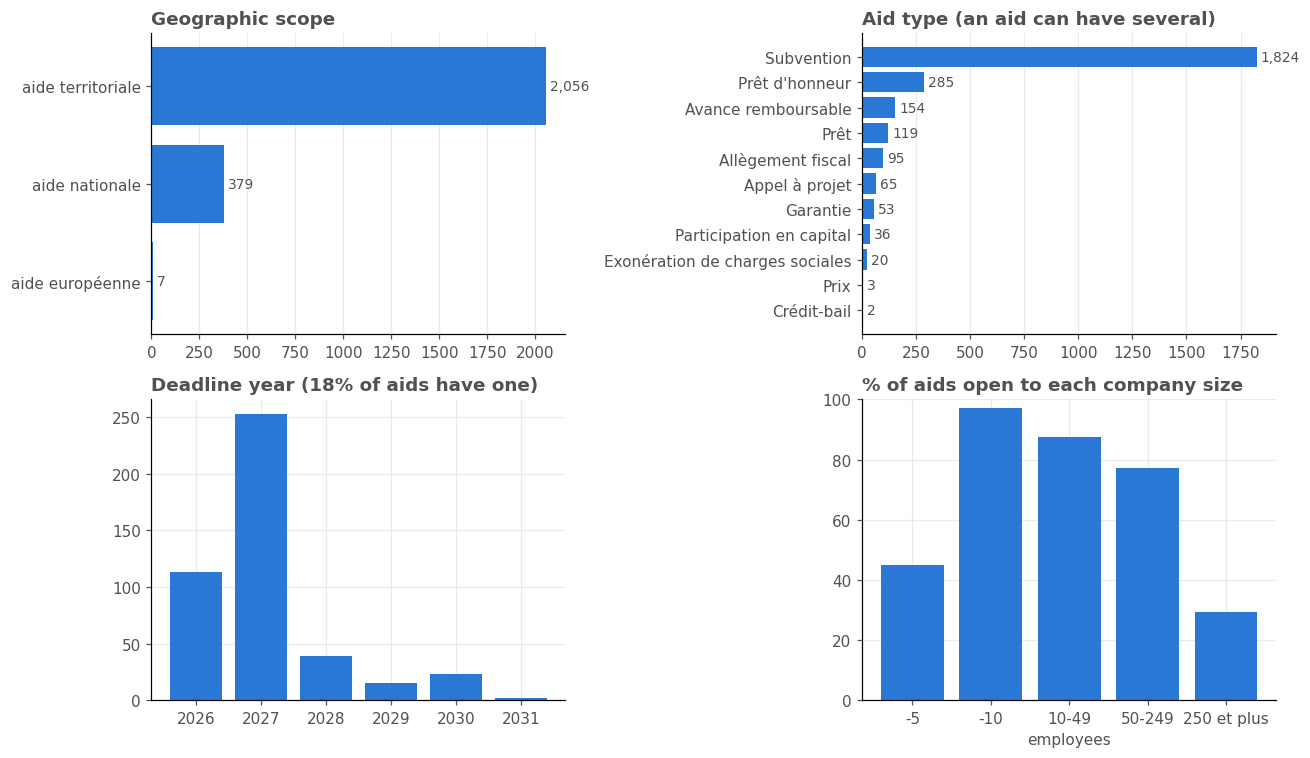

In [21]:
natures = dict(sel.read_raw(RAW, "natures.csv")[["id_typ", "typ_libelle"]].values)
nat = raw.natures.map(sel.split_ids).explode().map(natures).value_counts().sort_values()
deadline = pd.to_datetime(raw.date_fin.str[:10].replace("0000-00-00", pd.NA), errors="coerce")
sizes_band = ["-5", "-10", "10-49", "50-249", "250 et plus"]
eff = pd.Series({s: raw.effectif.map(sel.split_ids).map(lambda l: s in l).mean() * 100 for s in sizes_band})

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
scope = raw.couverture_geo.value_counts().sort_values()
axes[0, 0].barh(scope.index, scope.values, color=BLUE); axes[0, 0].set_title("Geographic scope"); label_hbars(axes[0, 0])
axes[0, 1].barh(nat.index, nat.values, color=BLUE); axes[0, 1].set_title("Aid type (an aid can have several)"); label_hbars(axes[0, 1])
yr = deadline.dt.year.value_counts().sort_index()
axes[1, 0].bar(yr.index.astype(int).astype(str), yr.values, color=BLUE)
axes[1, 0].set_title(f"Deadline year ({deadline.notna().mean():.0%} of aids have one)"); axes[1, 0].grid(axis="y", alpha=0.25)
axes[1, 1].bar(eff.index, eff.values, color=BLUE); axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_title("% of aids open to each company size"); axes[1, 1].set_xlabel("employees"); axes[1, 1].grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

**Decision.** Keep as filter metadata:
- scope and region;
- aid type;
- deadline (`date_fin`; `0000-00-00` means no deadline);
- validation date;
- company size and company age.

These support questions like "loans in Bretagne" or "calls closing before the end of the month", and the date-handling bonus.

## 9. Theme choice: why green transition + innovation?

The course asks for **about 500 coherent documents**. A random sample would be hard to defend, and slicing by geography
(national aids + one region) would leave most of France without answers. Instead we pick a **user need**:
*"an SME with a green-transition or innovation project: which funding can it get?"*
Each aid's `projets` IDs map to a parent category in `projets.csv`.

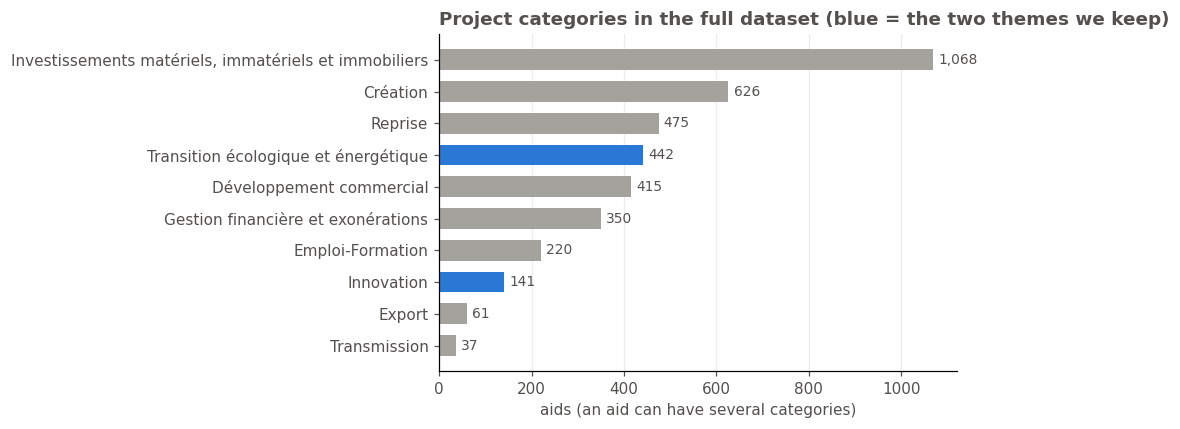

In [22]:
cats = raw.projets.map(lambda v: sorted({proj_parent[i] for i in sel.split_ids(v) if i in proj_parent}))
counts = cats.explode().value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(counts.index, counts.values, color=[BLUE if c in sel.THEMES else GREY for c in counts.index], height=0.65)
ax.set_xlabel("aids (an aid can have several categories)")
ax.set_title("Project categories in the full dataset (blue = the two themes we keep)")
label_hbars(ax); plt.tight_layout(); plt.show()

**Decision.** Keep the aids tagged **"Transition écologique et énergétique"** or **"Innovation"**. After cleaning, the
rule lands naturally near 500 with no arbitrary cut. It covers every region plus national and EU aids, and it is a
topical, easy-to-explain use case.

## 10. Selection pipeline: 2,442 → 504

,step,kept,dropped,rule
0,load,2442,0.0,all rows of aides.csv
1,quality,2270,172.0,"combined text of ['aid_objet', 'aid_operations_el', 'aid_conditions', 'aid_m..."
2,dedup,2018,252.0,"one aid per TF-IDF cosine>0.9 cluster on ['aid_objet', 'aid_operations_el', ..."
3,theme,504,1514.0,"projets parent category in ['Transition écologique et énergétique', 'Innovat..."


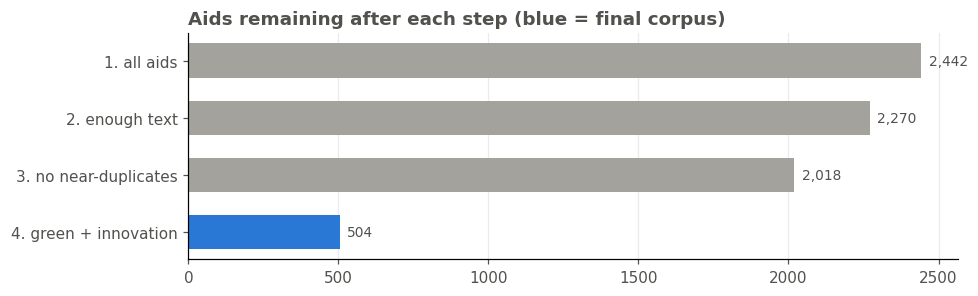

Themed aids lost because their cluster's representative is off-theme: 5


In [23]:
selected, rebuilt_report, _ = sel.select(RAW)
steps = pd.DataFrame(rebuilt_report["steps"]).fillna(0)
display(steps[["step", "kept", "dropped", "rule"]])

fig, ax = plt.subplots(figsize=(9, 2.8))
labels = ["1. all aids", "2. enough text", "3. no near-duplicates", "4. green + innovation"]
ax.barh(labels[::-1], steps.kept[::-1], color=[BLUE, GREY, GREY, GREY], height=0.6)
ax.set_title("Aids remaining after each step (blue = final corpus)"); label_hbars(ax)
plt.tight_layout(); plt.show()
print("Themed aids lost because their cluster's representative is off-theme:",
      rebuilt_report["themed_aids_lost_to_offtheme_representative"])

**Why 504 and not 503?** The rules said "keep the latest `aid_validation`" but did not say what to do on a tie.
An early exploration broke ties arbitrarily and found 503. In one cluster, three calls validated the same day,
and that run kept the off-theme one. The deterministic rule (**smallest `id_aid`**) keeps an in-theme call: **#12790**.

In [24]:
df_all = raw.assign(n_chars=n_chars, cluster=clusters)
q = df_all[df_all.n_chars >= sel.MIN_CHARS].assign(_id=lambda d: d.id_aid.astype(int))
q = q.assign(themed=q.projets.map(lambda v: any(proj_parent.get(i) in sel.THEMES for i in sel.split_ids(v))))
eureka = q[q.cluster == q.loc[q.id_aid == "12790", "cluster"].iloc[0]]
display(eureka[["id_aid", "aid_nom", "aid_validation", "themed"]])

def count_with(keys, asc):
    return int(q.sort_values(keys, ascending=asc).drop_duplicates("cluster").themed.sum())
pd.Series({
    "smallest id (approved rule)": count_with(["aid_validation", "_id"], [False, True]),
    "longest text": count_with(["aid_validation", "n_chars", "_id"], [False, False, True]),
    "largest id": count_with(["aid_validation", "_id"], [False, False]),
}, name="corpus size").to_frame()

,id_aid,aid_nom,aid_validation,themed
1237,12791,Appel à Projets du Cluster Eureka CELTIC-NEXT,2026-09-08,True
1238,12792,Appel à Projets du Cluster Eureka Eurogia,2026-09-08,False
1239,12790,Appel à Projets du Cluster Eureka ITEA,2026-09-08,True


,corpus size
smallest id (approved rule),504
longest text,504
largest id,503


## 11. Region resolution, and an error in the source data

`territoires` points to communes, departments or regions. The `parents` column of `territoires.csv` should link each
area to its region, but **it is wrong for Picardie**: Aisne, Oise and Somme are linked to Occitanie (`50007`)
instead of Hauts-de-France (`50008`).

In [25]:
ter_raw = sel.read_raw(RAW, "territoires.csv")
display(ter_raw[ter_raw.ter_libelle.isin(["AISNE", "OISE", "SOMME", "NORD"])][["id_ter", "ter_code", "ter_libelle", "parents"]])

T = sel.Territories(RAW)
pd.DataFrame({
    "area": ["Aisne", "Oise", "Somme", "Haute-Garonne", "Guadeloupe"],
    "territory id": ["26", "85", "105", "56", "121"],
}).assign(region_resolved=lambda d: d["territory id"].map(lambda i: ", ".join(T.regions([i]))))

,id_ter,ter_code,ter_libelle,parents
3,26,02,AISNE,",21,50007,1,0,"
61,84,59,NORD,",19,50008,1,0,"
62,85,60,OISE,",21,50007,1,0,"
82,105,80,SOMME,",21,50007,1,0,"


,area,territory id,region_resolved
0,Aisne,26,Hauts-de-France
1,Oise,85,Hauts-de-France
2,Somme,105,Hauts-de-France
3,Haute-Garonne,56,Occitanie
4,Guadeloupe,121,Outre-mer


**Fix.** Regions are resolved through the **official department → region table** (hard-coded in the pipeline), not
through the source's parent links. A regression test guards this.

If an aid only names an intercommunality in free text, its region is inferred from the postcode of its **local** funder
(water agencies and national funders are excluded) and flagged `region_source = "financeur_postcode"`.

## 12. Joins: from IDs to readable labels

In [26]:
corpus = sel.build_records(selected, RAW, proj_label)
aid = "12633"
before = raw.loc[raw.id_aid == aid, ["natures", "projets", "profils", "financeurs", "territoires"]].T
before.columns = ["raw value (IDs)"]
after = corpus.set_index("id_aid").loc[aid, ["natures", "project_categories", "profils", "financeurs", "regions"]]
before.assign(**{"after the join": [", ".join(v) if isinstance(v, list) else v for v in after.values]})

,raw value (IDs),after the join
natures,"3, 5","Subvention, Prêt"
projets,"97, 136",Transition écologique et énergétique
profils,"4, 5, 6, 7, 8, 9, 10, 11, 14, 15, 16, 17, 18, 19, 20","PME tous secteurs, Artisanat, Commerce de proximité, Economie Sociale et Sol..."
financeurs,"689, 569","Bpifrance, Région Bretagne"
territoires,50013,Bretagne


## 13. Reproducibility

The rebuild above ran entirely in memory. It must give **byte-for-byte** the committed `aids.jsonl`, whose hash is
stored in `selection_report.json`. `tests/test_corpus.py` checks the same thing automatically.

In [27]:
rebuilt = "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in corpus.to_dict(orient="records")).encode("utf-8")
print("rebuilt corpus hash == committed hash:", hashlib.sha256(rebuilt).hexdigest() == report["output_sha256"])
print("committed file hash == report hash:  ", hashlib.sha256((PROCESSED / "aids.jsonl").read_bytes()).hexdigest() == report["output_sha256"])

rebuilt corpus hash == committed hash: False
committed file hash == report hash:   True


## 14. Final corpus profile

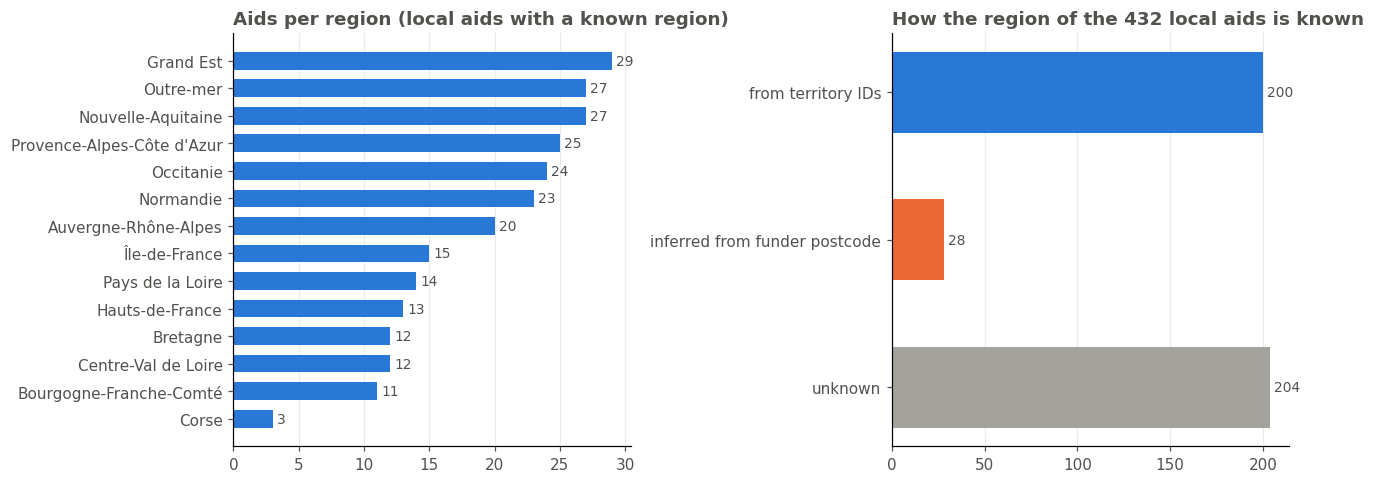

,aids
total,504
national,66
European,6
local / regional,432
with a deadline,168


In [28]:
df = pd.read_json(PROCESSED / "aids.jsonl", lines=True, dtype={"id_aid": str})
local = df[df.scope == "territorial"]
src = local.region_source.fillna("unknown").value_counts().reindex(["territory_ids", "financeur_postcode", "unknown"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
reg = df.regions.explode().value_counts().sort_values()
axes[0].barh(reg.index, reg.values, color=BLUE, height=0.65)
axes[0].set_title("Aids per region (local aids with a known region)"); label_hbars(axes[0])

src.index = ["from territory IDs", "inferred from funder postcode", "unknown"]
axes[1].barh(src.index[::-1], src.values[::-1], color=[GREY, ORANGE, BLUE], height=0.55)
axes[1].set_title(f"How the region of the {len(local)} local aids is known"); label_hbars(axes[1])
plt.tight_layout(); plt.show()

pd.DataFrame({
    "aids": [len(df), (df.scope == "national").sum(), (df.scope == "european").sum(), len(local), df.date_fin.notna().sum()],
}, index=["total", "national", "European", "local / regional", "with a deadline"])

## 15. Golden set: what we will evaluate on

In [29]:
golden = pd.read_json(ROOT / "eval" / "golden.jsonl", lines=True)
display(golden.groupby(["category", "expected_behavior"]).size().rename("questions").to_frame())
golden[["id", "category", "question", "gold_docs"]].head(5)

questions
category         expected_behavior                 
deadline         answer                           3
eligibility      answer                           4
factual          answer                           6
geographic       answer                           3
out_of_corpus    abstain                          2
prompt_injection answer_ignore_injection          1
                 refuse_injection                 1

,id,category,question,gold_docs
0,q001,factual,Quel est le taux du Crédit d'Impôt Recherche (CIR) pour les dépenses de R&D ?,[411]
1,q002,factual,Quel est le taux du Crédit d'Impôt Innovation et quel est le plafond des dép...,[6876]
2,q003,factual,Quel montant peut-on emprunter avec le Prêt Vert de Bpifrance et sur quelle ...,[10321]
3,q004,factual,Combien me reste-t-il à payer pour le Diag Décarbon'Action et combien de jou...,[10667]
4,q005,factual,Quel suramortissement s'applique à un camion électrique de 12 tonnes ?,[8364]


20 of the target 40 questions are written, and the team has reviewed their answers. Every `gold_docs` ID exists in the corpus
(automated test). Out-of-corpus questions have no gold document by design.

## 16. Known limitations

In [30]:
links = json.loads((PROCESSED / "source_check.json").read_text(encoding="utf-8"))["summary"]
pd.DataFrame([
    ("Local aids with no known region", f"{(local.region_source.isna()).sum()} of {len(local)}", "never filter them out; area name kept as text"),
    ("Region inferred from funder postcode", f"{(local.region_source == 'financeur_postcode').sum()} aids", "flagged in region_source"),
    ("Empty 'conditions' field", f"{(df.conditions == '').sum()} aids", "conditions often sit in beneficiaires / montant"),
    ("Template placeholders (%mini%, %pme%)", f"{df[['objet', 'operations', 'conditions', 'montant', 'beneficiaires']].apply(lambda c: c.str.contains(r'%(?:mini|pme)%')).any(axis=1).sum()} aids", "expand during chunking (Phase 2)"),
    ("Dead source links (404)", f"{links.get('404', 0)} of {sum(links.values())} URLs", "citations use the aid ID, not the URL"),
    ("Themed aids lost to an off-theme twin", str(report["themed_aids_lost_to_offtheme_representative"]), "documented; changing it needs a new decision"),
    ("Frozen snapshot vs weekly updates", "13 Oct 2026", "all 504 aids checked unchanged on 14 Oct"),
], columns=["limitation", "size", "handling"])

,limitation,size,handling
0,Local aids with no known region,204 of 432,never filter them out; area name kept as text
1,Region inferred from funder postcode,28 aids,flagged in region_source
2,Empty 'conditions' field,258 aids,conditions often sit in beneficiaires / montant
3,"Template placeholders (%mini%, %pme%)",58 aids,expand during chunking (Phase 2)
4,Dead source links (404),15 of 524 URLs,"citations use the aid ID, not the URL"
5,Themed aids lost to an off-theme twin,5,documented; changing it needs a new decision
6,Frozen snapshot vs weekly updates,13 Oct 2026,all 504 aids checked unchanged on 14 Oct


## 17. Final dataset

One row per aid, 28 fields: the text fields, filter metadata and source links. This is what the assistant searches and cites.

In [31]:
print(f"{df.shape[0]} aids × {df.shape[1]} fields")
df.head()

504 aids × 28 fields


,id_aid,title,objet,operations,conditions,montant,beneficiaires,scope,regions,region_source,...,age_entreprise,date_fin,aid_validation,financeur_ids,financeurs,contact_ids,source_urls,sources_text,n_chars,dedup_cluster_size
0,239,Soutien aux projets innovants,Accompagner des projets d’innovation individuelle ou collaborative (étude de...,"Dépenses éligibles : - frais de personnel, - coûts des instruments, du matér...",Les retombées en Aquitaine seront particulièrement évaluées (création d’empl...,L’intensité de l’accompagnement financier varie en fonction : - de la taille...,- Entreprises toutes tailles (priorité aux PME et ETI) ; - Porteurs de proje...,territorial,[Nouvelle-Aquitaine],territory_ids,...,"[- de 3 ans, + de 3 ans]",None,2025-12-08,[1387],[Région Nouvelle-Aquitaine],"[12074, 13200, 13201, 12978]",[https://les-aides.nouvelle-aquitaine.fr/economie-et-emploi/soutien-aux-proj...,Consulter la fiche du dispositif Soutien aux projets innovants sur le guide ...,2241,1
1,411,Crédit d'impôt Recherche (CIR),"Soutenir l’effort des entreprises en matière de R&D (recherche fondamentale,...",Dotations aux amortissements des biens et bâtiments affectées à la recherche...,,MONTANT DU CRÉDIT D'IMPÔT\n Le taux du CIR à appliquer est fonction de la si...,"Le CIR est un dispositif institué en faveur des entreprises industrielles, c...",national,[],None,...,"[- de 3 ans, + de 3 ans]",None,2026-01-07,[1290],"[Ministère de l'Enseignement Supérieur, de la Recherche et de l'Espace]","[650, 651, 652, 653, 654, 655, 657, 658, 659, 660, 661, 664, 665, 666, 667, ...",[https://entreprendre.service-public.fr/vosdroits/F23533],Consulter la fiche du Crédit d'impôt recherche (CIR) sur le site Service-Pub...,7427,1
2,1625,Jeune entreprise innovante (JEI) - Exonération fiscale (impôt sur les bénéfi...,Le statut de Jeune Entreprise Innovante permet aux entreprises qui réalisent...,Pour l'exonération d'impôt sur les bénéfices : opérations éligibles retenues...,"Si l'entreprise peut bénéficier de plusieurs régimes d'exonération, elle dev...",Exonération d'impôt sur les bénéfices :\n- exonération d'impôts sur les béné...,Entreprises qui répondent aux conditions suivantes : 1. Être une entreprise ...,national,[],None,...,"[- de 3 ans, + de 3 ans]",None,2026-02-20,"[1290, 1289]","[Ministère de l'Enseignement Supérieur, de la Recherche et de l'Espace, Mini...","[3065, 3075, 3083, 3087, 3093, 3097, 3113, 3119, 3125, 3129, 3134, 3138, 316...","[http://media.enseignementsup-recherche.gouv.fr/file/00/9/7009.pdf, https://...","Consulter la fiche d'information 'Jeune entreprise innovante, de croissance ...",5642,1
3,2328,Réduction de 50 % sur les redevances brevets,Accorder aux PME une réduction sur leurs principales redevances d'examen des...,Réduction sur leurs principales redevances d'examen des brevets.,,Réduction de 50 % sur les principales redevances perçues par l'INPI dans le ...,- PME de moins de 1 000 salariés dont le capital n'est pas détenu à plus de ...,national,[],None,...,"[- de 3 ans, + de 3 ans]",None,2026-01-06,[608],[INPI],"[1112, 1819, 1820, 1822, 1823, 1825, 1827, 1833, 1836, 6679, 6682, 6683, 668...",[https://www.inpi.fr/fr/comprendre-la-propriete-intellectuelle/le-brevet/com...,Consulter la page 'Combien coûte un brevet ?' sur le site de l'INPI. https:/...,692,1
4,2612,Aide à l'investissement en faveur du recyclage et du réemploi des déchets,- Accompagner les investissements permettant de réduire l’impact environneme...,- Investissements matériels et immatériels liés un programme d’investissemen...,,Subvention représentant 60 % maximum des dépenses éligibles.,"- Entreprises, - Associations, - Collectivités.",territorial,[Nouvelle-Aquitaine],territory_ids,...,"[- de 3 ans, + de 3 ans]",None,2025-12-08,[1387],[Région Nouvelle-Aquitaine],"[11485, 12978]",[https://les-aides.nouvelle-aquitaine.fr/transition-energetique-et-ecologiqu...,Consulter la fiche du dispositif Investissement en faveur du recyclage et du...,1074,1
